In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 150

In [2]:
DATA_DIR = Path("..")

orders = pd.read_csv(DATA_DIR / "olist_orders_dataset.csv")
customers = pd.read_csv(DATA_DIR / "olist_customers_dataset.csv")
payments = pd.read_csv(DATA_DIR / "olist_order_payments_dataset.csv")

In [3]:
delivered_orders = orders[orders["order_status"] == "delivered"].copy()

payments_agg = (payments.groupby("order_id")["payment_value"].sum().reset_index())

orders_revenue_df = delivered_orders.merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="inner",
)

orders_revenue_df = orders_revenue_df.merge(payments_agg, on="order_id", how="inner")

# Parse timestamps
orders_revenue_df["order_purchase_timestamp"] = pd.to_datetime(orders_revenue_df["order_purchase_timestamp"])

# Data integrity checks
assert (
    orders_revenue_df["order_id"].is_unique
), "Error: Duplicate order IDs present."
assert (
    orders_revenue_df["payment_value"].min() > 0
), "Error: Non-positive payment values detected."
assert (
    orders_revenue_df["customer_unique_id"].notna().all()
), "Error: Missing customer IDs detected."

print(f"{len(orders_revenue_df):,} verified delivered orders loaded.")
orders_revenue_df.head(5)

96,477 verified delivered orders loaded.


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,payment_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,38.71
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,af07308b275d755c9edb36a90c618231,141.46
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,3a653a41f6f9fc3d2a113cf8398680e8,179.12
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,7c142cf63193a1473d2e66489a9ae977,72.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,72632f0f9dd73dfee390c9b22eb56dd6,28.62


In [4]:
# Monthly order volume check
monthly_volume = (
    orders_revenue_df["order_purchase_timestamp"]
    .dt.to_period("M")
    .value_counts()
    .sort_index()
)

print("Monthly Delivered Order Volume:")
print(monthly_volume.head(8))

Monthly Delivered Order Volume:
order_purchase_timestamp
2016-10     265
2016-12       1
2017-01     750
2017-02    1653
2017-03    2546
2017-04    2303
2017-05    3546
2017-06    3135
Freq: M, Name: count, dtype: int64


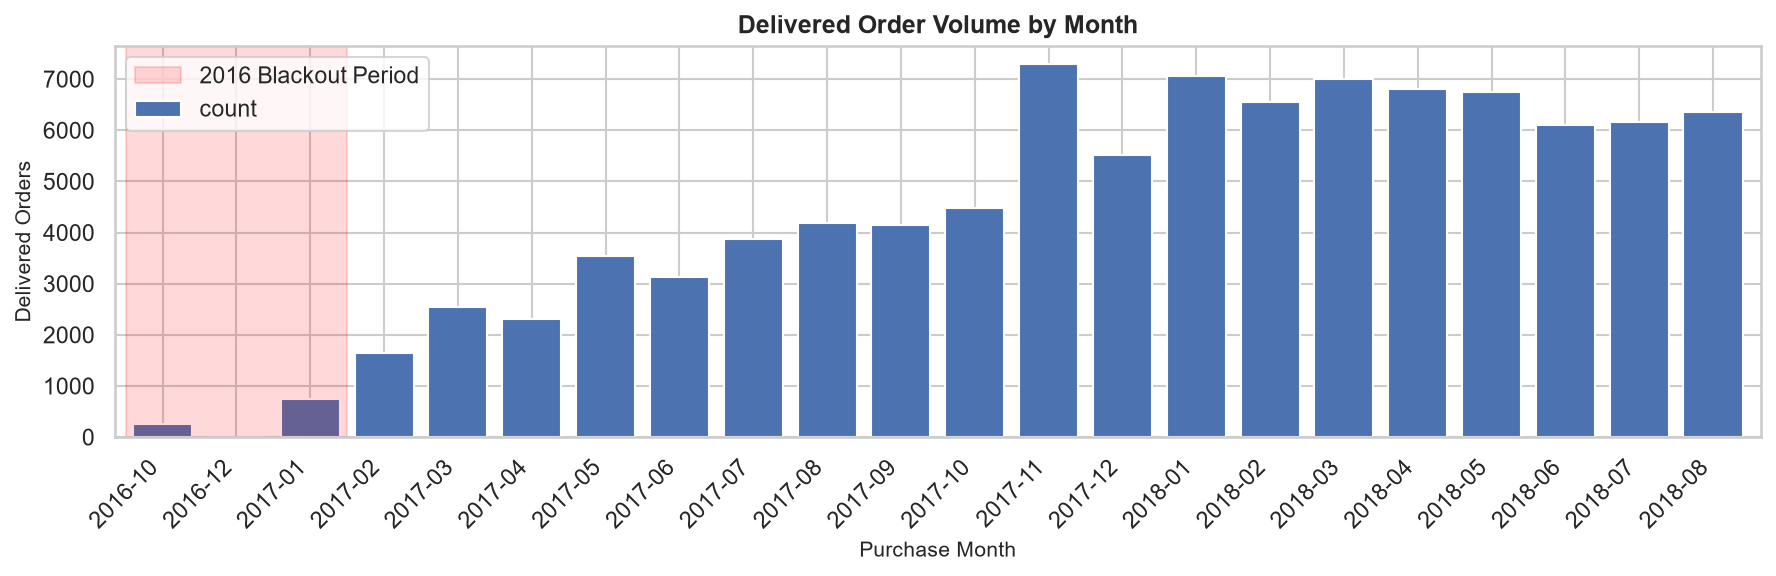

In [5]:
plt.figure(figsize=(12, 4))
monthly_volume.plot(kind="bar", color="#4C72B0", width=0.8)

plt.title(
    "Delivered Order Volume by Month",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Purchase Month", fontsize=10)
plt.ylabel("Delivered Orders", fontsize=10)
plt.xticks(rotation=45, ha="right")

plt.axvspan(-0.5, 2.5, color="red", alpha=0.15, label="2016 Blackout Period")
plt.legend()
plt.tight_layout()
plt.show()

Cohort Groups & Tenure Index

In [6]:
# Truncate order date to Year-Month period
orders_revenue_df["order_month"] = orders_revenue_df["order_purchase_timestamp"].dt.to_period("M")

# Month 0 (baseline) per unique customer
orders_revenue_df["cohort_group"] = orders_revenue_df.groupby("customer_unique_id")["order_month"].transform(
    "min"
)

# Filter out 2016 blackout period
cutoff_period = pd.Period("2017-01", freq="M")
cohort_df = orders_revenue_df[orders_revenue_df["cohort_group"] >= cutoff_period].copy()

# Cohort Index
year_diff = orders_revenue_df["order_month"].dt.year - orders_revenue_df["cohort_group"].dt.year
month_diff = orders_revenue_df["order_month"].dt.month - orders_revenue_df["cohort_group"].dt.month
cohort_df["cohort_index"] = year_diff * 12 + month_diff

assert cohort_df["cohort_index"].min() == 0, "Error: Negative cohort index!"
assert cohort_df["cohort_group"].min() >= cutoff_period, (
    "Error: 2016 data leaked!"
)

cohort_df[
    [
        "customer_unique_id",
        "order_purchase_timestamp",
        "cohort_group",
        "order_month",
        "cohort_index",
    ]
].head(5)

,customer_unique_id,order_purchase_timestamp,cohort_group,order_month,cohort_index
0,7c396fd4830fd04220f754e42b4e5bff,2017-10-02 10:56:33,2017-09,2017-10,1
1,af07308b275d755c9edb36a90c618231,2018-07-24 20:41:37,2018-07,2018-07,0
2,3a653a41f6f9fc3d2a113cf8398680e8,2018-08-08 08:38:49,2018-08,2018-08,0
3,7c142cf63193a1473d2e66489a9ae977,2017-11-18 19:28:06,2017-11,2017-11,0
4,72632f0f9dd73dfee390c9b22eb56dd6,2018-02-13 21:18:39,2018-02,2018-02,0


Percentage Retention Matrix

In [8]:
# Aggregate unique active buyers per cohort group and tenure index
cohort_data = (
    cohort_df.groupby(["cohort_group", "cohort_index"])["customer_unique_id"]
    .nunique()
    .reset_index()
)

# Pivot to tabular matrix
cohort_counts = cohort_data.pivot(
    index="cohort_group", columns="cohort_index", values="customer_unique_id"
)

# Extract baseline Month 0 cohort size
cohort_sizes = cohort_counts.iloc[:, 0]

# Divide across axis to get retention percentages
retention_matrix = cohort_counts.divide(cohort_sizes, axis=0) * 100

# Inspect the raw percentage table
retention_matrix.round(2).fillna("")

cohort_index,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,19
cohort_group,,,,,,,,,,,,,,,,,,,
2017-01,100.0,0.28,0.28,0.14,0.42,0.14,0.42,0.14,0.14,,0.42,0.14,0.7,0.42,0.14,0.14,0.28,0.42,0.14
2017-02,100.0,0.18,0.31,0.12,0.43,0.12,0.25,0.18,0.12,0.18,0.12,0.31,0.12,0.18,0.12,0.06,0.06,0.18,
2017-03,100.0,0.44,0.36,0.4,0.36,0.16,0.16,0.32,0.32,0.08,0.36,0.12,0.2,0.12,0.16,0.24,0.08,0.12,
2017-04,100.0,0.62,0.22,0.18,0.27,0.27,0.35,0.31,0.31,0.18,0.27,0.09,0.04,0.04,0.09,0.09,0.13,,
2017-05,100.0,0.46,0.46,0.29,0.29,0.32,0.41,0.14,0.26,0.26,0.26,0.35,0.23,0.03,0.17,0.2,,,
2017-06,100.0,0.49,0.4,0.43,0.3,0.4,0.36,0.23,0.13,0.2,0.3,0.36,0.16,0.16,0.23,,,,
2017-07,100.0,0.53,0.35,0.24,0.29,0.21,0.32,0.11,0.19,0.27,0.21,0.29,0.13,0.24,,,,,
2017-08,100.0,0.69,0.35,0.27,0.35,0.52,0.3,0.27,0.15,0.15,0.25,0.2,0.12,,,,,,
2017-09,100.0,0.7,0.55,0.27,0.45,0.22,0.22,0.25,0.27,0.17,0.25,0.07,,,,,,,


Retention Heatmap

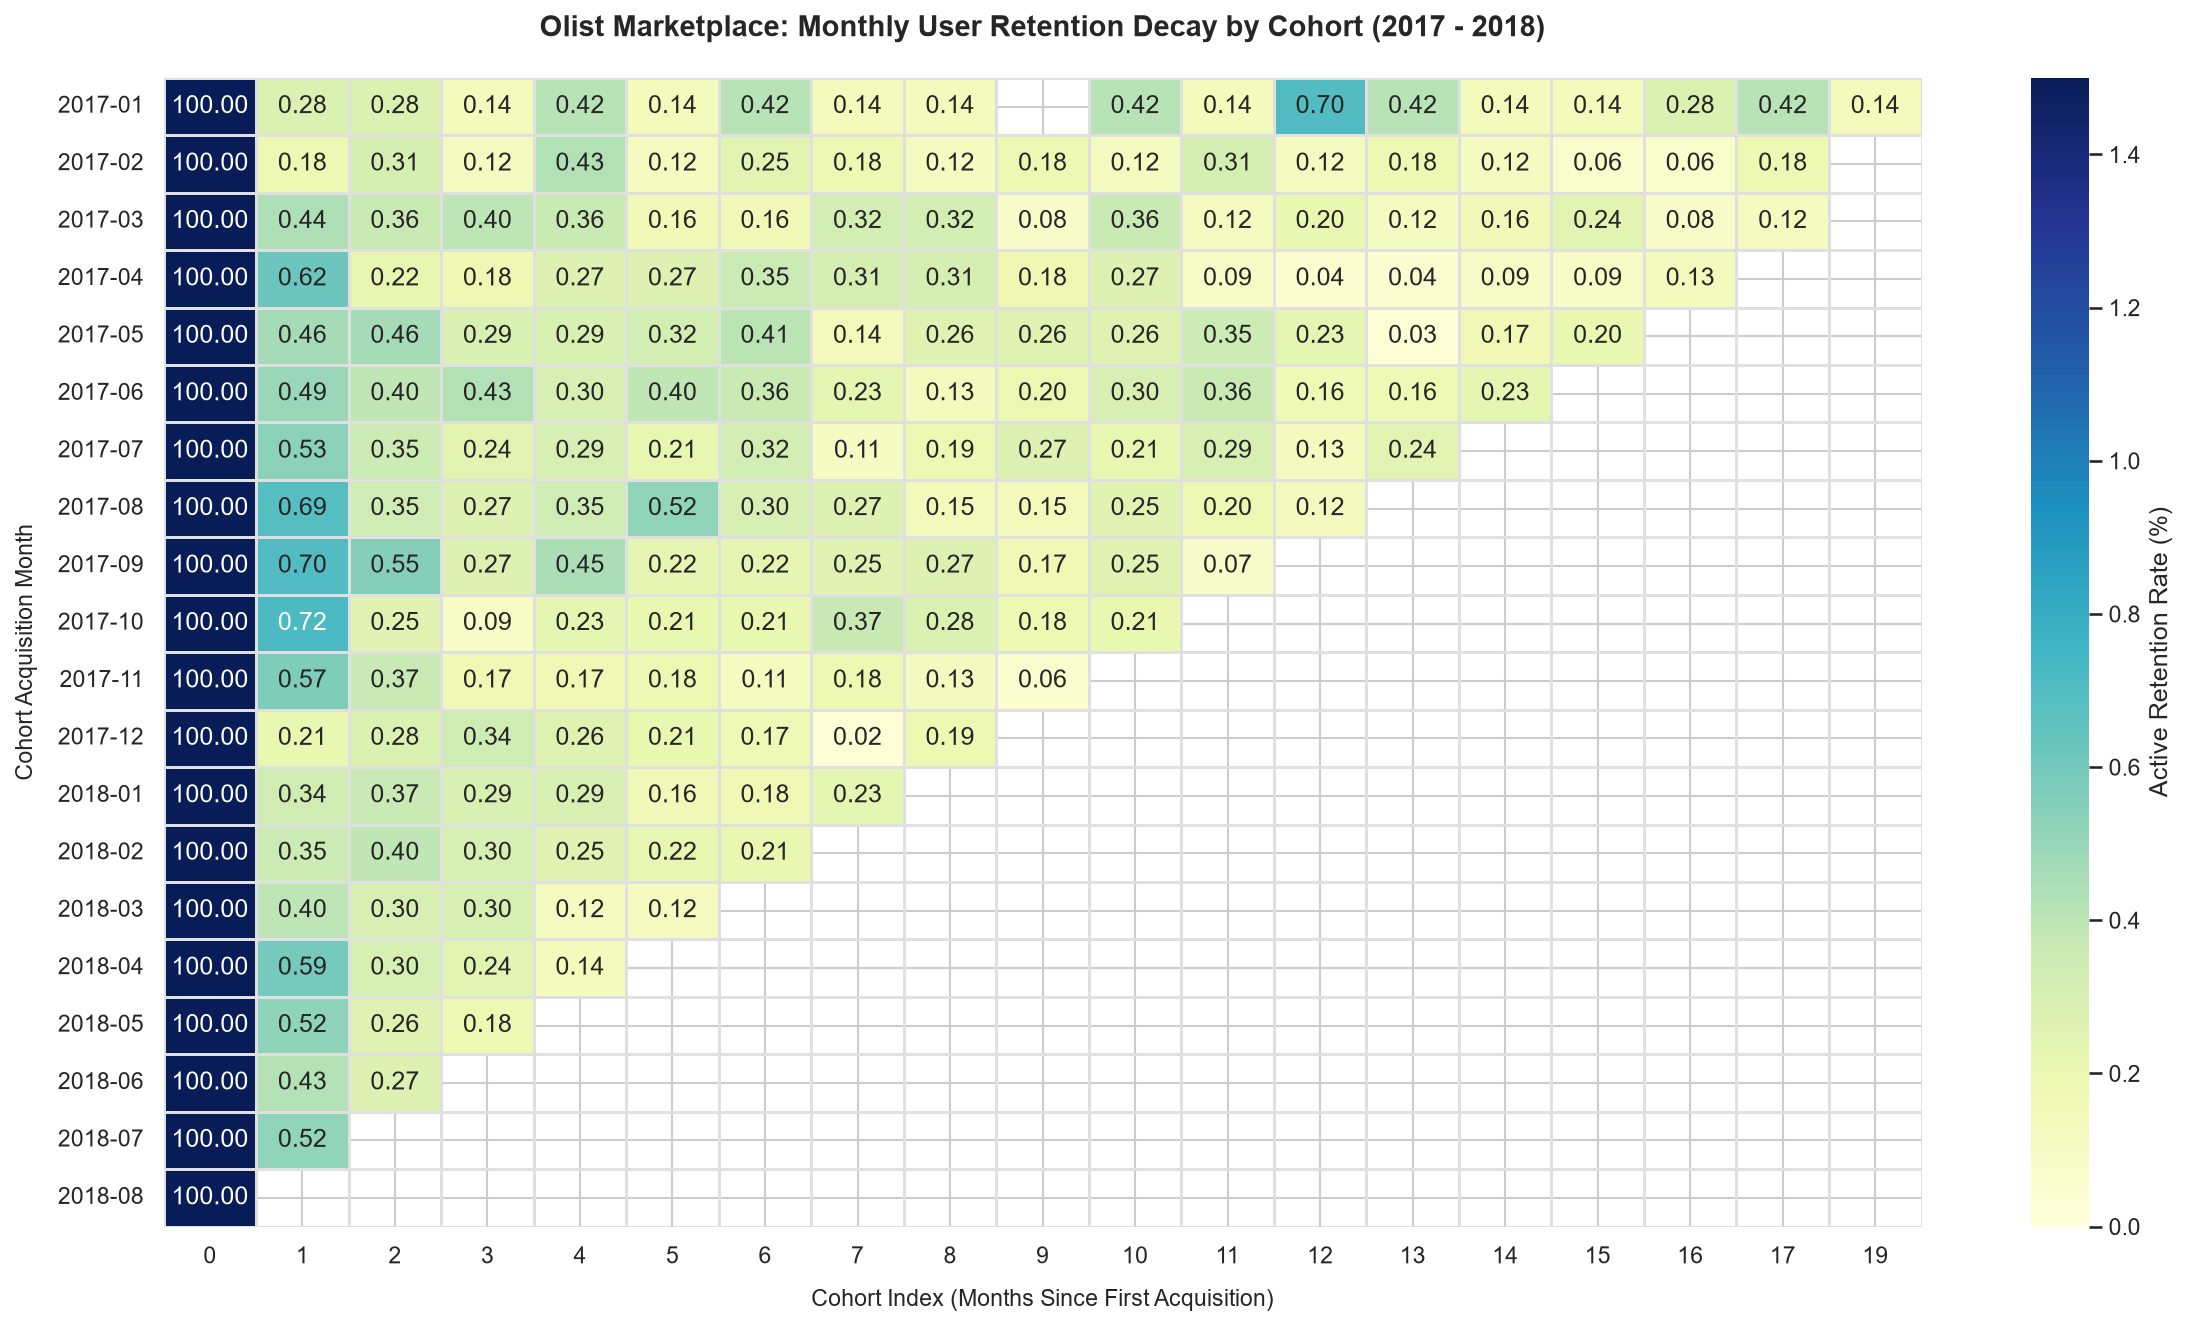

Heatmap exported successfully to: ..\reports\figures\olist_retention_heatmap.png


In [ ]:
plt.figure(figsize=(16, 9))
plt.title(
    "Olist Marketplace: Monthly User Retention Decay by Cohort (2017 - 2018)",
    fontsize=14,
    fontweight="bold",
    pad=20,
)

ax = sns.heatmap(
    retention_matrix,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    vmin=0.0,
    vmax=1.5,    # Note: vmax=1.5 is crucial, standard 0-100 scales wash out the 0.2% - 0.7% retention tail
    cbar_kws={"label": "Active Retention Rate (%)"},
    linewidths=0.5,
    linecolor="#e0e0e0",
)

plt.xlabel("Cohort Index (Months Since First Acquisition)", fontsize=11, labelpad=10)
plt.ylabel("Cohort Acquisition Month", fontsize=11, labelpad=10)
plt.yticks(rotation=0)

# Export chart
output_path = Path("../reports/figures/olist_retention_heatmap.png")
output_path.parent.mkdir(parents=True, exist_ok=True)
plt.tight_layout()
plt.savefig(output_path, dpi=300)
plt.show()

print(f"Heatmap exported successfully to: {output_path}")

Cumulative LTV Calculation

In [9]:
# Filter for mature cohorts that have at least 12 complete months of history 
mature_cutoff = pd.Period("2017-08", freq="M")       # Note: dataset end in Aug 2018, if min 12mths, only Aug 2017 and before is possible
mature_cohort_df = cohort_df[
    (cohort_df["cohort_group"] <= mature_cutoff) & (cohort_df["cohort_index"] <= 12)
].copy()

# Baseline acquisition cohort sizes (total unique customers entering in Month 0)
cohort_sizes = (
    mature_cohort_df[mature_cohort_df["cohort_index"] == 0]
    .groupby("cohort_group")["customer_unique_id"]
    .nunique()
)

# Sum total gross merchandise value / revenue generated per cohort per month
cohort_revenue = (
    mature_cohort_df.groupby(["cohort_group", "cohort_index"])["payment_value"]
    .sum()
    .unstack(fill_value=0.0)
)

# Incremental spend per acquired customer: Revenue / Initial Cohort Size
incremental_ltv = cohort_revenue.divide(cohort_sizes, axis=0)

# Cumulate horizontally across tenure months (0 through 12)
cumulative_ltv = incremental_ltv.cumsum(axis=1)

# Inspect mean trajectory across all mature cohorts
ltv_profile = cumulative_ltv.mean(axis=0)

print("Cumulative Realized LTV Profile (BRL):")
for month, val in ltv_profile.items():
    print(f"Month {month:02d}: R$ {val:.2f}")

Cumulative Realized LTV Profile (BRL):
Month 00: R$ 163.73
Month 01: R$ 164.45
Month 02: R$ 164.95
Month 03: R$ 165.31
Month 04: R$ 165.76
Month 05: R$ 166.20
Month 06: R$ 166.79
Month 07: R$ 167.06
Month 08: R$ 167.37
Month 09: R$ 167.62
Month 10: R$ 168.02
Month 11: R$ 168.34
Month 12: R$ 168.64


Unit Economics & Allowable CAC Thresholds

In [10]:
TAKE_RATE = 0.15          # Olist estimated platform commission (15%)
TARGET_LTV_CAC_RATIO = 3.0 # Healthy benchmark: LTV/CAC >= 3.0

# 12-Month Realized Gross LTV
gmv_ltv_12m = ltv_profile.loc[12]

# Platform Net Revenue LTV
net_revenue_ltv_12m = gmv_ltv_12m * TAKE_RATE

# Maximum Allowable CAC to maintain a 3:1 ratio
allowable_cac = net_revenue_ltv_12m / TARGET_LTV_CAC_RATIO

# One-time purchase contribution
m0_revenue = ltv_profile.loc[0]
repeat_contribution_pct = ((gmv_ltv_12m - m0_revenue) / gmv_ltv_12m) * 100

print(f"--- Strategic Unit Economics Summary ---")
print(f"12-Month Realized GMV per Customer:     R$ {gmv_ltv_12m:.2f}")
print(f"12-Month Platform Net Revenue (15%):   R$ {net_revenue_ltv_12m:.2f}")
print(f"Maximum Allowable CAC (3:1 Benchmark):  R$ {allowable_cac:.2f}")
print(f"Revenue Share from Repeat Purchases:    {repeat_contribution_pct:.2f}%")

--- Strategic Unit Economics Summary ---
12-Month Realized GMV per Customer:     R$ 168.64
12-Month Platform Net Revenue (15%):   R$ 25.30
Maximum Allowable CAC (3:1 Benchmark):  R$ 8.43
Revenue Share from Repeat Purchases:    2.91%


Cumulative LTV Trajectory Plot

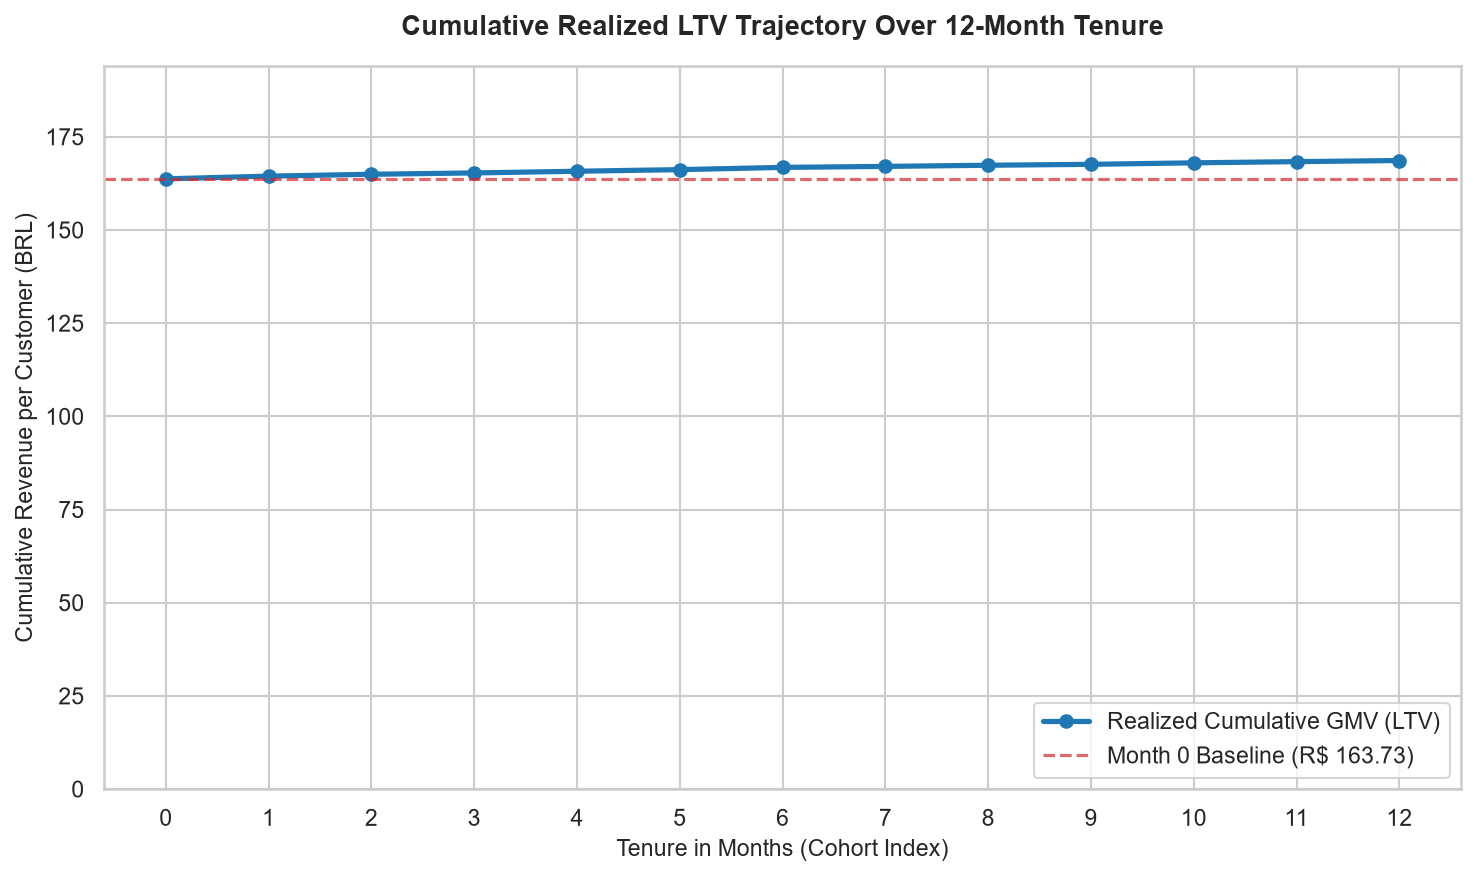

LTV trajectory plot exported to: ..\reports\figures\olist_cumulative_ltv_trajectory.png


In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    ltv_profile.index,
    ltv_profile.values,
    marker="o",
    linewidth=2.5,
    color="#1f77b4",
    label="Realized Cumulative GMV (LTV)",
)

# Highlight Month 0 vs Month 12
plt.axhline(
    y=ltv_profile.loc[0],
    color="#d62728",
    linestyle="--",
    alpha=0.7,
    label=f"Month 0 Baseline (R$ {ltv_profile.loc[0]:.2f})",
)

plt.title("Cumulative Realized LTV Trajectory Over 12-Month Tenure", fontsize=13, fontweight="bold", pad=15)
plt.xlabel("Tenure in Months (Cohort Index)", fontsize=11)
plt.ylabel("Cumulative Revenue per Customer (BRL)", fontsize=11)
plt.xticks(range(0, 13))
plt.ylim(0, ltv_profile.max() * 1.15)
plt.legend(loc="lower right", frameon=True)

# Export chart
ltv_plot_path = Path("../reports/figures/olist_cumulative_ltv_trajectory.png")
plt.tight_layout()
plt.savefig(ltv_plot_path, dpi=300)
plt.show()

print(f"LTV trajectory plot exported to: {ltv_plot_path}")